# Actividad extra. México, estado por estado (CENAPRED)

## Fuente

**CENAPRED · Atlas Nacional de Riesgos**, *Base histórica de impacto
socioeconómico 2000–2024* (`CENAPRED_impacto_2000_2024.xlsx`, 10,354 registros).
El archivo trae estado y municipios afectados, tipo de fenómeno, defunciones,
población afectada, viviendas, escuelas, hospitales, comercios, superficie de
cultivo y el total de daños **en millones de pesos**.

# Paso 1. Rutas y funciones del pipeline

Para no duplicar la lógica, el notebook reutiliza las funciones de
`src/mexico_estados.py`. El mismo módulo genera los archivos que consume la
app.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# La raíz del proyecto es la carpeta que contiene src/ y notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import APP_DATOS, RESULTADOS_GRAFICAS, RESULTADOS_TABLAS
from src.mexico_estados import (
    ARCHIVO_CENAPRED,
    CLASIFICACIONES_NATURALES,
    agregar_estados,
    agregar_series,
    cargar_cenapred,
    cargar_geojson,
    construir_destacados,
    explotar_estados,
    normalizar_estado,
    resumen_tipos,
)

GRAFICAS = RESULTADOS_GRAFICAS / "mexico"
GRAFICAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 20)

print(f"Raíz del proyecto: {RAIZ}")
print(f"Fuente           : {ARCHIVO_CENAPRED.name}")

Raíz del proyecto: C:\Users\itzel\PROYECTO_DESASTRES
Fuente           : CENAPRED_impacto_2000_2024.xlsx


# Paso 2. Leo la fuente

Antes de filtrar reviso cuántos registros hay, en qué periodo y cuántas
variantes de nombre de estado existen. Esos nombres son el primer problema de
calidad: la fuente escribe `CDMX`, `Distrito Federal` y `Ciudad de México` para
la misma entidad.

In [2]:
df = cargar_cenapred()

print(f"Registros           : {len(df):,}")
print(f"Periodo             : {df['anio'].min()} – {df['anio'].max()}")
print(f"Variantes de estado : {df['estado_crudo'].nunique()}")
print(f"Tipos distintos     : {df['tipo'].nunique()} (toda la fuente)")
df[["fecha_inicio", "clasificacion", "tipo", "estado_crudo", "dano_millones"]].head(8)

Registros           : 10,354
Periodo             : 2000 – 2024
Variantes de estado : 67
Tipos distintos     : 58 (toda la fuente)


,fecha_inicio,clasificacion,tipo,estado_crudo,dano_millones
0,2000-12-18,Geológico,Actividad volcánica,"CDMX, Estado de Mexico, Morelos, Puebla, Tlaxcala",115.800
1,2000-06-01,Hidrometeorológico,Sequía,Aguascalientes,25.100
2,2000-01-01,Químico,Incendio forestal,Baja California,3.577
3,2000-09-16,Hidrometeorológico,Ciclón tropical,Baja California Sur,7.243
4,2000-09-30,Hidrometeorológico,Ciclón tropical,Chiapas,25.560
5,2000-01-04,Hidrometeorológico,Ciclón tropical,Chiapas,38.153
6,2000-06-01,Hidrometeorológico,Otros,Chiapas,55.511
7,2000-05-01,Hidrometeorológico,Sequía,Chihuahua,120.000


# Paso 3. Filtro de fenómenos naturales

La fuente clasifica los registros en cinco grupos. Solo tres corresponden a
fenómenos naturales. Los otros dos (sociorganizativos y químicos) son
accidentes, explosiones o fugas: se excluyen porque el atlas es de desastres
naturales.

Los **incendios forestales** aparecen como químicos en esta base; se dejan
fuera a propósito porque CONAFOR ya los cubre con mucho más detalle.

In [3]:
clasificaciones = df["clasificacion"].value_counts()
print(clasificaciones.to_string())

naturales = df[df["clasificacion"].isin(CLASIFICACIONES_NATURALES)].copy()
print(f"\nRegistros naturales: {len(naturales):,} ({100 * len(naturales) / len(df):.1f} % del total)")
print(f"Defunciones         : {naturales['defunciones'].sum():,.0f}")
print(f"Daño registrado     : {naturales['dano_millones'].sum() / 1e3:,.1f} mil M MXN")

clasificacion
Hidrometeorológico    3792
Sociorganizativo      3181
Químico               2991
Geológico              334
Sanitario               56

Registros naturales: 4,182 (40.4 % del total)
Defunciones         : 5,302
Daño registrado     : 693.2 mil M MXN


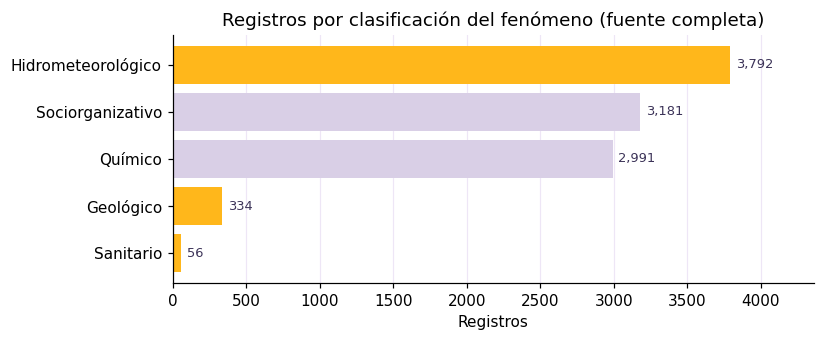

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 3.2))
orden = clasificaciones.sort_values()
colores = ["#ffb71b" if c in CLASIFICACIONES_NATURALES else "#d9cfe6" for c in orden.index]
ax.barh(orden.index, orden.values, color=colores)
for y, valor in enumerate(orden.values):
    ax.text(valor + 40, y, f"{valor:,}", va="center", fontsize=8.5, color="#3c3358")
ax.set_title("Registros por clasificación del fenómeno (fuente completa)")
ax.set_xlabel("Registros")
ax.set_xlim(0, orden.max() * 1.15)
ax.grid(axis="x", color="#eee6f6", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig(GRAFICAS / "05_clasificaciones.png", bbox_inches="tight")
plt.show()

# Paso 4. Homologación de estados

El GeoJSON trae 32 polígonos con `id` ISO y `name`. Cargo ese catálogo y
convierto cada variante de la fuente al nombre oficial.

Cuando un registro menciona varios estados (`Guerrero y Michoacán`) se reparte
en partes iguales: son 11 filas de 4,182, así que la aproximación pesa 0.3 %.
Las menciones `Todo el país` y `Varios Estados` no se pueden dibujar en un mapa
estatal y se descartan (solo 4 filas).

In [5]:
nombre_a_id, id_a_nombre = cargar_geojson()
print(f"Estados en el GeoJSON: {len(nombre_a_id)}")

variantes = sorted(df["estado_crudo"].dropna().astype(str).unique())
multiples = [v for v in variantes if normalizar_estado(v, nombre_a_id) is None]
print(f"Variantes en la fuente: {len(variantes)}")
print("Menciones múltiples o nacionales:")
for valor in multiples:
    print("  ·", valor)

largo, descartados = explotar_estados(naturales, nombre_a_id)
print(f"\nFilas estado-evento: {len(largo):,}")
print(f"Estados con datos   : {largo['iso'].nunique()}")
print(f"Descartados         : {descartados}")

Estados en el GeoJSON: 32


Variantes en la fuente: 67
Menciones múltiples o nacionales:
  · Baja California Sur, Chichuahua y Michoacán
  · CDMX, Estado de Mexico, Morelos, Puebla, Tlaxcala
  · CDMX, Morelos y Sonora
  · Chiapas, Michoacan, Nuevo Leon, Quintana Roo
  · Chihuahua, Durango, Estado de Mexico, Puebla, Sonora, Tlaxcala
  · Coahuila, Chiapas, Distrito Federal, Hidalgo, Nayarit, Nuevo Leon, Oaxaca, Veracruz
  · Coahuila, Chihuahua
  · Colima, Chiapas, Guerrero y Michoacán
  · Michoacán, Oaxaca, Sonora, Veracruz y Zacatecas
  · Nayarit y Campeche
  · Oaxaca, Tamaulipas, Veracruz
  · Tabasco y Veracruz
  · Tamaulipas, Veracruz
  · Todo el país
  · Varios Estados
  · Veracruz y Tamaulipas 



Filas estado-evento: 4,195
Estados con datos   : 32
Descartados         : {'sin_estado': 0, 'nacional': 4}


# Paso 5. Homologación de tipos

La fuente escribe el mismo fenómeno con mayúsculas, espacios o acentos distintos.
El pipeline lo reduce a 34 etiquetas canónicas para que el selector de la app
no tenga opciones repetidas.

In [6]:
conteo_tipos = naturales["tipo"].value_counts()
print(f"Tipos canónicos: {conteo_tipos.size}")
print(conteo_tipos.head(12).to_string())

Tipos canónicos: 34
tipo
Lluvias                2112
Bajas temperaturas      361
Temperatura extrema     322
Ciclón tropical         234
Tormenta severa         171
Inundación              161
Sequía                  155
Fuertes vientos         130
Deslizamiento           110
Remoción en masa         97
Sismo                    58
Helada                   58


# Paso 6. Agregados por estado

Cada estado acumula eventos, defunciones, afectados, daños, viviendas, escuelas,
hospitales, comercios y hectáreas de cultivo. También calculo su lugar nacional
y su participación en el daño total.

La tabla confirma el peso de Guerrero (Otis), Veracruz (muchos eventos),
Tabasco (inundaciones) y la Ciudad de México (sismo de 2017).

In [7]:
estados = agregar_estados(largo, id_a_nombre)
tabla = pd.DataFrame(estados.values()).sort_values("dano_mxn", ascending=False)
tabla["dano_mm"] = tabla["dano_mxn"] / 1e9

tabla[
    ["nombre", "eventos", "defunciones", "afectados", "dano_mm", "viviendas", "ranking_dano"]
].head(10).round({"dano_mm": 1})

,nombre,eventos,defunciones,afectados,dano_mm,viviendas,ranking_dano
10,Guerrero,228,331.0,3258825.0,131.1,497982.0,1
29,Veracruz,405,361.0,8165019.0,80.0,466443.0,2
26,Tabasco,80,90.0,3511416.0,71.9,390454.0,3
5,Chiapas,331,318.0,4459176.0,56.2,168508.0,4
6,Ciudad de México,123,265.0,1899817.0,45.3,28337.0,5
19,Oaxaca,236,391.0,3842456.0,44.6,253704.0,6
2,Baja California Sur,70,73.0,2132724.0,35.1,30223.0,7
18,Nuevo León,83,255.0,8081226.0,29.0,31058.0,8
22,Quintana Roo,58,67.0,538000.0,26.1,49952.0,9
23,Sinaloa,118,61.0,1358348.0,14.5,21431.0,10


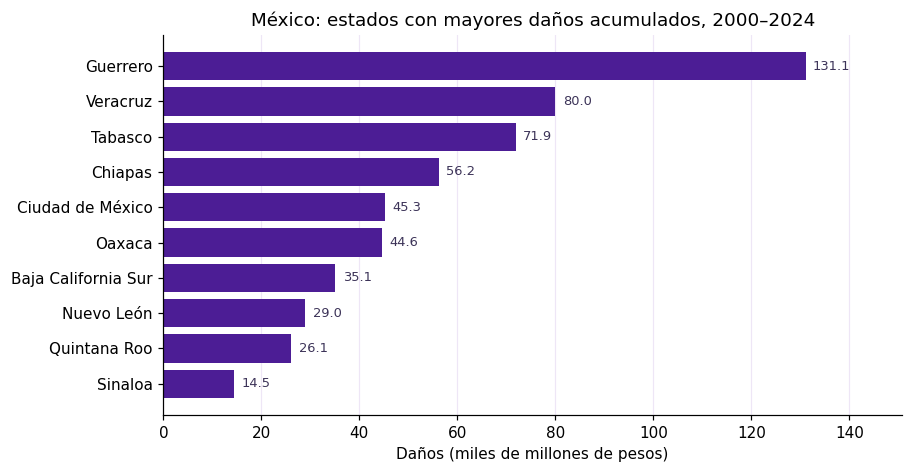

In [8]:
top = tabla.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.barh(top["nombre"], top["dano_mm"], color="#4c1d95")
for y, (valor, nombre) in enumerate(zip(top["dano_mm"], top["nombre"])):
    ax.text(valor + 1.5, y, f"{valor:,.1f}", va="center", fontsize=8.5, color="#3c3358")
ax.set_title("México: estados con mayores daños acumulados, 2000–2024")
ax.set_xlabel("Daños (miles de millones de pesos)")
ax.set_xlim(0, top["dano_mm"].max() * 1.15)
ax.grid(axis="x", color="#eee6f6", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig(GRAFICAS / "06_estados_dano.png", bbox_inches="tight")
plt.show()

# Paso 7. Series por año y tipo

La app no vuelve a leer el Excel: recibe una serie compacta por estado con
`[año, tipo, daño, defunciones, afectados, viviendas]`. Con eso los filtros de
variable, rango de años y tipo se resuelven en el navegador, sin recargar.

Aquí reviso la serie nacional para ver los años atípicos.

In [9]:
por_anio, por_tipo, nacional = agregar_series(largo)
tipos = resumen_tipos(largo)

nac = pd.DataFrame(
    [
        {"anio": int(anio), "eventos": v[0], "dano_mm": v[1] / 1e9, "defunciones": v[2]}
        for anio, v in nacional.items()
    ]
)
nac.sort_values("dano_mm", ascending=False).head(5).round({"dano_mm": 1})

,anio,eventos,dano_mm,defunciones
10,2010,188,91.2,259.0
17,2017,97,87.7,570.0
23,2023,138,87.5,515.0
13,2013,170,57.3,312.0
7,2007,178,50.5,259.0


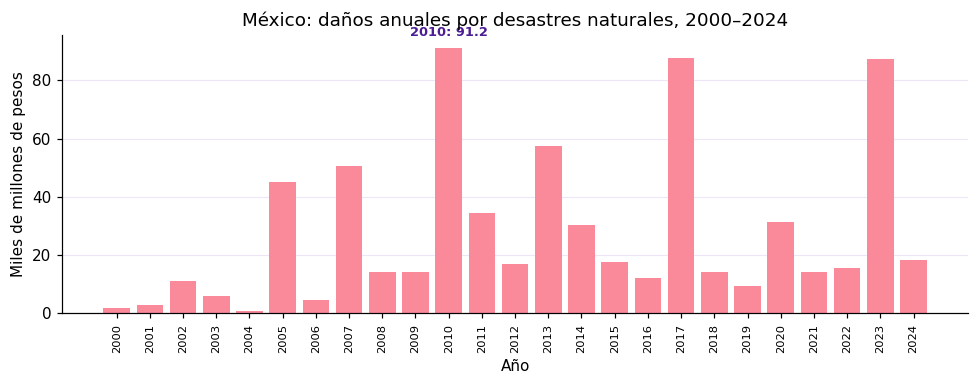

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(nac["anio"], nac["dano_mm"], color="#fa8a9a")
maximo = nac.loc[nac["dano_mm"].idxmax()]
ax.annotate(
    f"{int(maximo['anio'])}: {maximo['dano_mm']:,.1f}",
    xy=(maximo["anio"], maximo["dano_mm"]),
    xytext=(0, 8),
    textcoords="offset points",
    ha="center",
    fontsize=8.5,
    color="#4c1d95",
    fontweight="bold",
)
ax.set_title("México: daños anuales por desastres naturales, 2000–2024")
ax.set_xlabel("Año")
ax.set_ylabel("Miles de millones de pesos")
ax.set_xticks(nac["anio"])
ax.tick_params(axis="x", rotation=90, labelsize=7.5)
ax.grid(axis="y", color="#eee6f6", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig(GRAFICAS / "07_dano_por_anio.png", bbox_inches="tight")
plt.show()

# Paso 8. Los cuatro desastres destacados

Para la exposición se eligen cuatro eventos que muestran fenómenos distintos y
dos escalas: el huracán más caro, el sismo más letal, y dos inundaciones del
mismo estado con 13 años de diferencia.

* **Huracán Otis (2023, Guerrero).** El evento más costoso de toda la serie y
  el 64.2 % del daño acumulado de Guerrero.
* **Sismo del 19S (2017, Ciudad de México).** El de mayor impacto humano en la
  capital: 228 defunciones y el 97.1 % del daño de la Ciudad de México.
* **Inundación de Tabasco 2007.** 8 municipios y el 44.3 % del daño estatal.
* **Inundación de Tabasco 2020.** 14 municipios y 10 defunciones: el contraste
  reciente con 2007.

La ficha se localiza por **fecha + tipo + estado**, no por texto, para no
confundirla con otro evento parecido.

In [11]:
destacados = construir_destacados(largo, estados)

fichas = pd.DataFrame(
    [
        {
            "titulo": d["titulo"],
            "estado": d["estado"],
            "fecha": d["fecha"],
            "municipios": d["num_municipios"],
            "dano_mm": round(d["dano_mxn"] / 1e9, 1),
            "defunciones": int(d["defunciones"]),
            "participacion_estatal": d["participacion_estatal"],
        }
        for d in destacados
    ]
)
fichas

,titulo,estado,fecha,municipios,dano_mm,defunciones,participacion_estatal
0,Huracán Otis,Guerrero,2023-10-24,2,84.2,52,64.2
1,Sismo del 19S,Ciudad de México,2017-09-19,1,44.0,228,97.1
2,Inundación de Tabasco 2007,Tabasco,2007-10-24,8,31.9,0,44.3
3,Inundación de Tabasco 2020,Tabasco,2020-10-29,14,13.6,10,18.9


# Paso 9. Validación

Compruebo que la suma de los 32 estados coincida con la suma de las filas
estatales, que no haya daños negativos, que los cuatro eventos se hayan
encontrado y que todas las claves ISO existan en el GeoJSON.

También verifico la diferencia con la fuente: **4 registros** dicen `Todo el
país` o `Varios Estados`. No se pueden dibujar en un mapa estatal, así que se
excluyen del mapa (equivalen a 6.2 mil millones de pesos, 121 defunciones y
508 mil afectados). El resto de la diferencia es el reparto de los 11 registros
multiestado.

**Advertencia metodológica importante:** CENAPRED y EM-DAT no son comparables.
EM-DAT reporta alrededor de **1.6 billones de pesos** para México en el mismo
periodo; CENAPRED reporta **687 mil millones** para fenómenos naturales. Cambian
la cobertura, la clasificación y la metodología de valoración. Por eso la vista
de México usa CENAPRED y la vista mundial sigue usando EM-DAT; no se suman ni
se presentan como la misma cifra.

In [12]:
total_natural = naturales["dano_millones"].sum() * 1e6
total_estados = sum(e["dano_mxn"] for e in estados.values())
total_largo = largo["dano_millones"].sum() * 1e6

nacionales = naturales[
    naturales["estado_crudo"].astype(str).str.strip().isin(["Todo el país", "Varios Estados"])
]
excluido_dano = nacionales["dano_millones"].sum() * 1e6
excluido_def = nacionales["defunciones"].sum()

print(f"Daño en la fuente (naturales) : {total_natural:,.0f} MXN")
print(f"Daño en las filas estatales   : {total_largo:,.0f} MXN")
print(f"Suma de los 32 estados        : {total_estados:,.0f} MXN")
print(f"Registros nacionales excluidos: {len(nacionales)}")
print(f"  daño                        : {excluido_dano:,.0f} MXN")
print(f"  defunciones                 : {excluido_def:,.0f}")

comprobaciones = {
    "32 estados en la tabla": len(estados) == 32,
    "sin daños negativos": bool((tabla["dano_mxn"] >= 0).all()),
    "cuatro fichas encontradas": len(destacados) == 4,
    "suma estatal = filas estatales": abs(total_estados - total_largo) < 100,
    "diferencia = registros nacionales": abs((total_natural - total_largo) - excluido_dano) < 1,
    "defunciones cuadran": abs(
        (naturales["defunciones"].sum() - largo["defunciones"].sum()) - excluido_def
    ) < 0.01,
    "claves ISO completas": set(tabla["iso"]) == set(nombre_a_id.values()),
}
for nombre, ok in comprobaciones.items():
    print(("OK    " if ok else "FALLA ") + nombre)
assert all(comprobaciones.values()), "Hay una comprobación que falló"
print("\nTodas las comprobaciones pasaron.")

Daño en la fuente (naturales) : 693,205,290,839 MXN
Daño en las filas estatales   : 686,972,825,839 MXN
Suma de los 32 estados        : 686,972,825,838 MXN
Registros nacionales excluidos: 4
  daño                        : 6,232,465,000 MXN
  defunciones                 : 121
OK    32 estados en la tabla
OK    sin daños negativos
OK    cuatro fichas encontradas
OK    suma estatal = filas estatales
OK    diferencia = registros nacionales
OK    defunciones cuadran
OK    claves ISO completas

Todas las comprobaciones pasaron.


# Paso 10. Exportación


In [13]:
from src.mexico_estados import main

main()

1. Leyendo CENAPRED…


   10,354 registros · 2000–2024
2. Filtrando fenómenos naturales…
   4,182 registros naturales
3. Homologando estados…


   4,195 filas estado-evento · 32 estados · 4 menciones nacionales · 0 sin identificar
4. Agregando indicadores…


   Nacional: 4,195 eventos · 5,181 defunciones · 687.0 mil M MXN
5. mexico_estados.json (253 KB)
  estados_mexico.geojson  (179 KB)
6. mexico_estados_resumen.csv (32 estados)

Destacados:
   Huracán Otis: Guerrero · 84.2 mil M MXN · 52 defunciones
   Sismo del 19S: Ciudad de México · 44.0 mil M MXN · 228 defunciones
   Inundación de Tabasco 2007: Tabasco · 31.9 mil M MXN · 0 defunciones
   Inundación de Tabasco 2020: Tabasco · 13.6 mil M MXN · 10 defunciones


In [14]:
archivos = [
    APP_DATOS / "mexico_estados.json",
    APP_DATOS / "estados_mexico.geojson",
    RESULTADOS_TABLAS / "mexico_estados_resumen.csv",
]
for ruta in archivos:
    print(f"{ruta.relative_to(RAIZ)}  {ruta.stat().st_size / 1024:,.0f} KB")

datos = json.loads((APP_DATOS / "mexico_estados.json").read_text(encoding="utf-8"))
print("\nBloques del JSON:", ", ".join(datos.keys()))
print("Estados          :", len(datos["estados"]))
print("Fichas           :", len(datos["destacados"]))
print("Daño total       :", f"{datos['total']['dano_mxn'] / 1e9:,.1f} mil M MXN")

app\datos\mexico_estados.json  253 KB
app\datos\estados_mexico.geojson  179 KB
resultados\tablas\mexico_estados_resumen.csv  2 KB

Bloques del JSON: meta, total, estados, por_anio, por_tipo, serie, top_eventos, nacional_por_anio, tipos, destacados
Estados          : 32
Fichas           : 4
Daño total       : 687.0 mil M MXN


# Paso 11. La vista en la aplicación

La pestaña **México** del panel abre una vista de pantalla completa con:

* **Mapa coroplético** de los 32 estados (MapLibre GL).
* **Filtros** de variable (daños, defunciones, afectados, eventos, viviendas),
  rango de años y tipo de fenómeno.
* **Panel estatal** con participación nacional, KPIs y los eventos más costosos
  del filtro actual.
* **Cuatro fichas** de desastres con su detalle y un botón para centrar el
  estado en el mapa.

Reviso que las piezas estén conectadas en el HTML, el CSS y el JavaScript.

In [15]:
from pathlib import Path

# Rutas autocontenidas: la celda funciona aunque no se ejecute el Paso 1.
raiz = RAIZ if "RAIZ" in globals() else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
html = (raiz / "app" / "index.html").read_text(encoding="utf-8")
js = (raiz / "app" / "js" / "mexico_estados.js").read_text(encoding="utf-8")
css = (raiz / "app" / "css" / "estilos.css").read_text(encoding="utf-8")

piezas = {
    "pestaña México": 'data-pestana="mexico"' in html,
    "vista de pantalla completa": 'id="vista-mexico"' in html,
    "contenedor del mapa": 'id="mapa-mexico"' in html,
    "modal de desastre": 'id="modal-desastre"' in html,
    "script cargado": "mexico_estados.js" in html,
    "lectura del JSON": "mexico_estados.json" in js,
    "fichas destacadas": "destacados" in js,
    "estilos de la vista": ".mexico-vista" in css,
}
for nombre, ok in piezas.items():
    print(("OK    " if ok else "FALLA ") + nombre)
assert all(piezas.values())


OK    pestaña México
OK    vista de pantalla completa
OK    contenedor del mapa
OK    modal de desastre
OK    script cargado
OK    lectura del JSON
OK    fichas destacadas
OK    estilos de la vista



La vista de México queda integrada con **4,195 filas estado-evento**, 32
estados, **5,181 defunciones**, **59.8 millones de afectados** y **687 mil
millones de pesos** en daños (2000–2024, solo fenómenos naturales).
